# Boston Housing Dataset – Lineare Regression

Ziel des Projekts ist es, den durchschnittlichen Hauspreis in Boston
auf Basis verschiedener sozioökonomischer und infrastruktureller Merkmale vorherzusagen.
(z. B. Anzahl Zimmer, Entfernung zum Arbeitszentrum, Luftverschmutzung usw.).



## 1. Import wichtiger Bibliotheken

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

## 2. Datenimport und erste Exploration
In diesem Abschnitt wird der Datensatz geladen und ein erster Überblick über Struktur und Kennzahlen gewonnen.

### 2.1 Datensatz laden

In [11]:
data_path = "data/train.csv"

df = pd.read_csv(data_path)
df.head()

,ID,crim,zn,indus,chas,nox,rm,age,dis,rad,tax,ptratio,black,lstat,medv
0,1,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296,15.3,396.90,4.98,24.0
1,2,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242,17.8,396.90,9.14,21.6
2,4,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222,18.7,394.63,2.94,33.4
3,5,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222,18.7,396.90,5.33,36.2
4,7,0.08829,12.5,7.87,0,0.524,6.012,66.6,5.5605,5,311,15.2,395.60,12.43,22.9


Hier lade ich den Datensatz und zeige die ersten Zeilen. Jede Zeile entspricht einem Haus.
Die Spalten sind die Merkmale. Ganz rechts sehen wir medv, also den Hauspreis, den wir vorhersagen möchten.

**Beobachtung:** Hier sieht man einen klaren positiven Zusammenhang zwischen Zimmeranzahl und Preis. Das erklärt, warum lineare Modelle grundsätzlich funktionieren können.

### 2.2 Überblick über Struktur und Kennzahlen

In [12]:
df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 333 entries, 0 to 332
Data columns (total 15 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   ID       333 non-null    int64  
 1   crim     333 non-null    float64
 2   zn       333 non-null    float64
 3   indus    333 non-null    float64
 4   chas     333 non-null    int64  
 5   nox      333 non-null    float64
 6   rm       333 non-null    float64
 7   age      333 non-null    float64
 8   dis      333 non-null    float64
 9   rad      333 non-null    int64  
 10  tax      333 non-null    int64  
 11  ptratio  333 non-null    float64
 12  black    333 non-null    float64
 13  lstat    333 non-null    float64
 14  medv     333 non-null    float64
dtypes: float64(11), int64(4)
memory usage: 39.2 KB


,ID,crim,zn,indus,chas,nox,rm,age,dis,rad,tax,ptratio,black,lstat,medv
count,333.000000,333.000000,333.000000,333.000000,333.000000,333.000000,333.000000,333.000000,333.000000,333.000000,333.000000,333.000000,333.000000,333.000000,333.000000
mean,250.951952,3.360341,10.689189,11.293483,0.060060,0.557144,6.265619,68.226426,3.709934,9.633634,409.279279,18.448048,359.466096,12.515435,22.768769
std,147.859438,7.352272,22.674762,6.998123,0.237956,0.114955,0.703952,28.133344,1.981123,8.742174,170.841988,2.151821,86.584567,7.067781,9.173468
min,1.000000,0.006320,0.000000,0.740000,0.000000,0.385000,3.561000,6.000000,1.129600,1.000000,188.000000,12.600000,3.500000,1.730000,5.000000
25%,123.000000,0.078960,0.000000,5.130000,0.000000,0.453000,5.884000,45.400000,2.122400,4.000000,279.000000,17.400000,376.730000,7.180000,17.400000
50%,244.000000,0.261690,0.000000,9.900000,0.000000,0.538000,6.202000,76.700000,3.092300,5.000000,330.000000,19.000000,392.050000,10.970000,21.600000
75%,377.000000,3.678220,12.500000,18.100000,0.000000,0.631000,6.595000,93.800000,5.116700,24.000000,666.000000,20.200000,396.240000,16.420000,25.000000
max,506.000000,73.534100,100.000000,27.740000,1.000000,0.871000,8.725000,100.000000,10.710300,24.000000,711.000000,21.200000,396.900000,37.970000,50.000000


Da der Datensatz weitgehend bereinigt ist, liegt der Fokus auf der Modellierung und nicht auf komplexer Vorverarbeitung.

## 3. Feature-Set und Train-Test-Split

Im nächsten Schritt trenne ich Zielvariable und Features
und teile die Daten in Trainings- und Testdaten auf.


### 3.1 Aufteilung der Daten

In [13]:
target_column = "medv"

X = df.drop(columns=[target_column])
y = df[target_column]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

80 % der Daten nutzt das Modell zum Lernen und 20 % behalten wir für die Bewertung.

## 4. Baseline-Modell: Lineare Regression

Als Baseline verwende ich eine lineare Regression, weil sie schnell,
einfach und gut interpretierbar ist. Danach trainiere ich das Modell
auf den Trainingsdaten und bewerte es auf den Testdaten mit RMSE und R².

Eine Feature-Skalierung wurde hier bewusst nicht eingesetzt, da lineare
Regression nicht sensitiv gegenüber unterschiedlichen Skalen ist.


In [14]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)


## 5. Modellbewertung

Das trainierte Regressionsmodell wird mithilfe des
Root Mean Squared Error (RMSE) und des Bestimmtheitsmaßes R² bewertet.


In [15]:
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("RMSE:", rmse)
print("R²:", r2)

RMSE: 4.838564025266008
R²: 0.7398653051224351


Das Modell wurde jetzt trainiert und erreicht einen RMSE von etwa 4,84. Der RMSE beschreibt die typische Größenordnung der Vorhersagefehler in derselben Einheit wie die Zielvariable und gewichtet größere Abweichungen stärker.

Der R²-Wert von etwa 0,74 bedeutet, dass das lineare Regressionsmodell auf diesem Testsplit rund 74 % der Varianz der Zielvariable erklärt. Damit liefert die lineare Regression eine brauchbare Baseline, bildet jedoch nicht alle Zusammenhänge im Datensatz ab.

## 6. Visualisierung der Ergebnisse

Zur visuellen Bewertung des Modells werden die vorhergesagten Werte den tatsächlichen Werten gegenübergestellt.


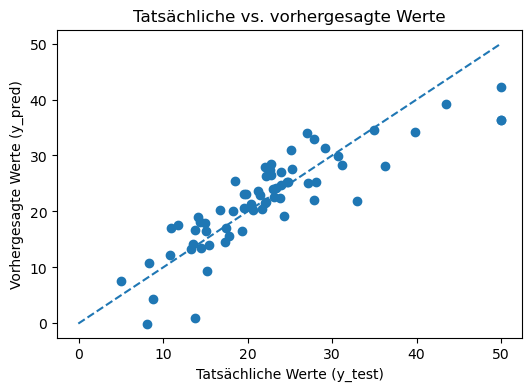

In [16]:
plt.figure(figsize=(6, 4))

plt.scatter(y_test, y_pred)

# Referenzlinie: perfekte Vorhersage (y = x)
min_value = min(y_test.min(), y_pred.min())
max_value = max(y_test.max(), y_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.xlabel("Tatsächliche Werte (y_test)")
plt.ylabel("Vorhergesagte Werte (y_pred)")
plt.title("Tatsächliche vs. vorhergesagte Werte")
plt.show()

Die Grafik stellt die tatsächlichen und vorhergesagten Werte gegenüber. Die gestrichelte Diagonale entspricht einer perfekten Vorhersage.

Viele Punkte liegen in der Nähe dieser Referenzlinie, gleichzeitig sind insbesondere bei einzelnen Beobachtungen deutliche Abweichungen sichtbar. Dies passt zu den Ergebnissen von RMSE und R² und zeigt, dass die lineare Regression einen grundlegenden Zusammenhang erfasst, aber nicht sämtliche Muster im Datensatz erklären kann.

### Zusammenhang zwischen Zimmerzahl und Zielvariable

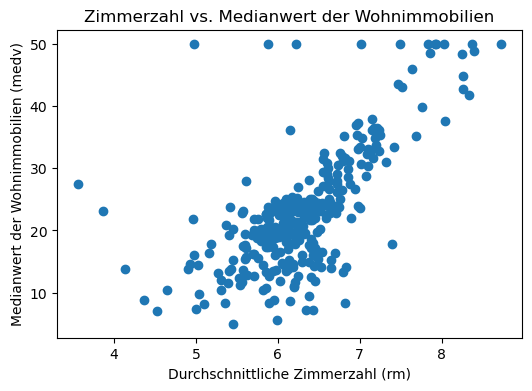

In [17]:
plt.figure(figsize=(6, 4))
plt.scatter(df["rm"], df["medv"])
plt.xlabel("Durchschnittliche Zimmerzahl (rm)")
plt.ylabel("Medianwert der Wohnimmobilien (medv)")
plt.title("Zimmerzahl vs. Medianwert der Wohnimmobilien")
plt.show()

Die Grafik zeigt einen positiven Zusammenhang zwischen der durchschnittlichen Zimmerzahl und der Zielvariable `medv`: Beobachtungen mit einer höheren durchschnittlichen Zimmerzahl weisen tendenziell höhere Werte auf.

Die Streuung zeigt zugleich, dass die Zielvariable nicht allein von der Zimmerzahl abhängt. Die Häufung bei `medv = 50` weist auf die Obergrenze der Zielvariable im Datensatz hin.

## 7. Verbesserung der Ergebnisse

Für bessere Ergebnisse könnten komplexere Modelle wie Random Forest oder Gradient Boosting eingesetzt werden. Zusätzlich könnte Cross-Validation verwendet werden, um die Robustheit der Modellbewertung zu erhöhen.

## 8. Fazit

Dieses Projekt zeigt einen vollständigen grundlegenden Regressions-Workflow: Datenimport und Exploration, Aufteilung in Trainings- und Testdaten, Training einer linearen Regression, Modellbewertung und Visualisierung der Ergebnisse.

Das Modell erreicht auf dem verwendeten Testsplit einen R²-Wert von etwa 0,74 und einen RMSE von etwa 4,84. Die lineare Regression stellt damit eine geeignete Baseline dar.

Als Erweiterung könnten nichtlineare Modelle wie Random Forest oder Gradient Boosting sowie Cross-Validation eingesetzt werden, um die Modellleistung und Robustheit systematischer zu untersuchen.